In [2]:
import pandas as pd
import glob

files = glob.glob('/content/*.csv')
print(files)

df = pd.read_csv(files[0])
display(df.head())
print(df.columns.tolist())
print(df.shape)

['/content/customer_churn_model_v2.csv']


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn
0,CUST-100001,57,South,33,Standard,767.25,23893.97,Month-to-Month,4,1,UPI,Yes,Yes
1,CUST-100002,44,South,45,Basic,476.72,21627.46,Two Year,0,1,UPI,Yes,Yes
2,CUST-100003,64,South,57,Basic,414.81,22500.07,One Year,1,1,UPI,No,Yes
3,CUST-100004,57,East,44,Pro,1171.76,50309.16,Month-to-Month,4,0,Card,Yes,Yes
4,CUST-100005,58,North,49,Pro,1130.19,55980.21,Month-to-Month,3,0,Wallet,No,No


['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']
(800, 13)


In [3]:
print("All Dataset Columns:")
for col in df.columns:
    print(col)

print("\nChurn Values:")
for col in df.columns:
    if "churn" in col.lower():
        print(col)
        print(df[col].value_counts())

All Dataset Columns:
CustomerID
Age
Region
TenureMonths
SubscriptionType
MonthlyChargesINR
TotalChargesINR
ContractType
SupportTickets
LatePayments
PaymentMethod
AutoPay
Churn

Churn Values:
Churn
Churn
No     466
Yes    334
Name: count, dtype: int64


In [4]:
# Check dataset information
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (800, 13)

Missing Values:
CustomerID           0
Age                  0
Region               0
TenureMonths         0
SubscriptionType     0
MonthlyChargesINR    0
TotalChargesINR      0
ContractType         0
SupportTickets       0
LatePayments         0
PaymentMethod        0
AutoPay              0
Churn                0
dtype: int64

Duplicate Records:
0

Data Types:
CustomerID            object
Age                    int64
Region                object
TenureMonths           int64
SubscriptionType      object
MonthlyChargesINR    float64
TotalChargesINR      float64
ContractType          object
SupportTickets         int64
LatePayments           int64
PaymentMethod         object
AutoPay               object
Churn                 object
dtype: object


In [5]:
# Check dataset information
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (800, 13)

Missing Values:
CustomerID           0
Age                  0
Region               0
TenureMonths         0
SubscriptionType     0
MonthlyChargesINR    0
TotalChargesINR      0
ContractType         0
SupportTickets       0
LatePayments         0
PaymentMethod        0
AutoPay              0
Churn                0
dtype: int64

Duplicate Records:
0

Data Types:
CustomerID            object
Age                    int64
Region                object
TenureMonths           int64
SubscriptionType      object
MonthlyChargesINR    float64
TotalChargesINR      float64
ContractType          object
SupportTickets         int64
LatePayments           int64
PaymentMethod         object
AutoPay               object
Churn                 object
dtype: object


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

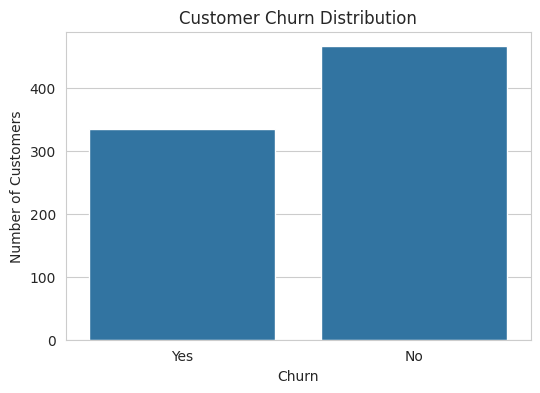

In [7]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

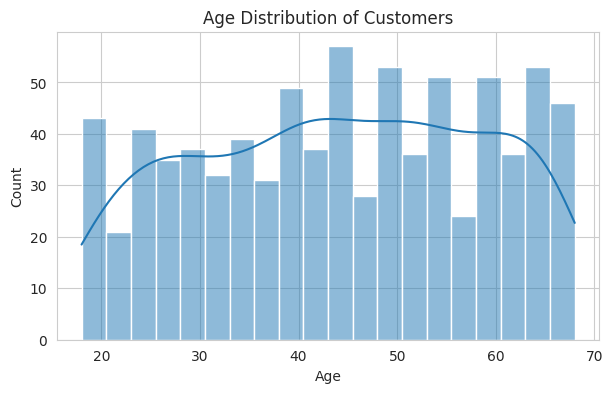

In [8]:
plt.figure(figsize=(7,4))

sns.histplot(df['Age'], bins=20, kde=True)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

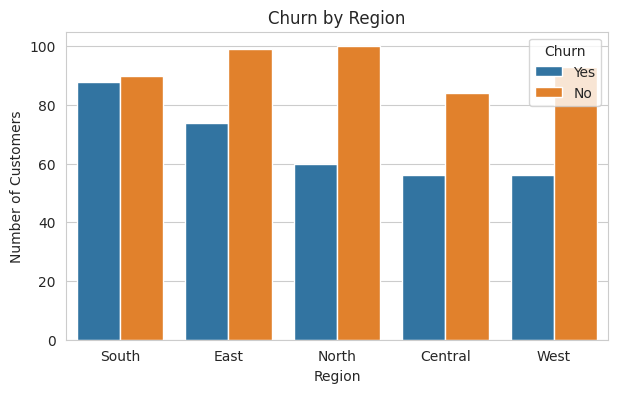

In [9]:
plt.figure(figsize=(7,4))

sns.countplot(data=df, x='Region', hue='Churn')

plt.title("Churn by Region")
plt.xlabel("Region")
plt.ylabel("Number of Customers")

plt.show()

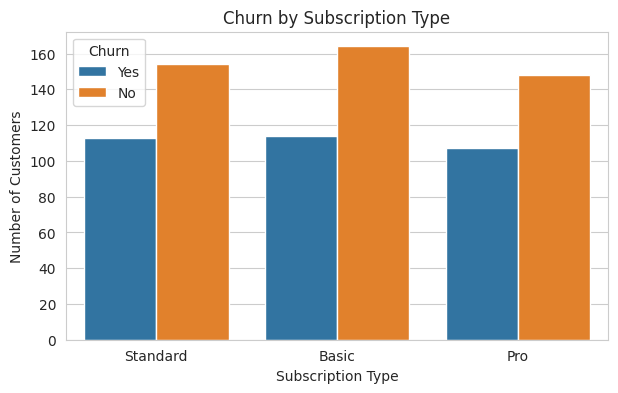

In [10]:
plt.figure(figsize=(7,4))

sns.countplot(data=df, x='SubscriptionType', hue='Churn')

plt.title("Churn by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")

plt.show()

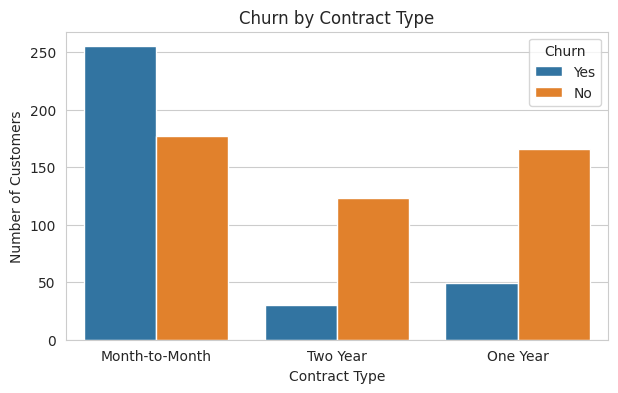

In [11]:
plt.figure(figsize=(7,4))

sns.countplot(data=df, x='ContractType', hue='Churn')

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [12]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

Missing Values:
CustomerID           0
Age                  0
Region               0
TenureMonths         0
SubscriptionType     0
MonthlyChargesINR    0
TotalChargesINR      0
ContractType         0
SupportTickets       0
LatePayments         0
PaymentMethod        0
AutoPay              0
Churn                0
dtype: int64

Dataset Shape:
(800, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         800 non-null    object 
 1   Age                800 non-null    int64  
 2   Region             800 non-null    object 
 3   TenureMonths       800 non-null    int64  
 4   SubscriptionType   800 non-null    object 
 5   MonthlyChargesINR  800 non-null    float64
 6   TotalChargesINR    800 non-null    float64
 7   ContractType       800 non-null    object 
 8   SupportTickets     800 non-null   

In [13]:
# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values
for col in df.select_dtypes(include=['number']).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Data preprocessing completed!")
print(df.isnull().sum().sum())

Data preprocessing completed!
0


In [14]:
df = pd.get_dummies(df, drop_first=True)

print("Categorical encoding completed!")
print(df.head())

Categorical encoding completed!
   Age  TenureMonths  MonthlyChargesINR  TotalChargesINR  SupportTickets  \
0   57            33             767.25         23893.97               4   
1   44            45             476.72         21627.46               0   
2   64            57             414.81         22500.07               1   
3   57            44            1171.76         50309.16               4   
4   58            49            1130.19         55980.21               3   

   LatePayments  CustomerID_CUST-100002  CustomerID_CUST-100003  \
0             1                   False                   False   
1             1                    True                   False   
2             1                   False                    True   
3             0                   False                   False   
4             0                   False                   False   

   CustomerID_CUST-100004  CustomerID_CUST-100005  ...  Region_West  \
0                   False            

In [19]:
print(df.columns.tolist())

['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments', 'CustomerID_CUST-100002', 'CustomerID_CUST-100003', 'CustomerID_CUST-100004', 'CustomerID_CUST-100005', 'CustomerID_CUST-100006', 'CustomerID_CUST-100007', 'CustomerID_CUST-100008', 'CustomerID_CUST-100009', 'CustomerID_CUST-100010', 'CustomerID_CUST-100011', 'CustomerID_CUST-100012', 'CustomerID_CUST-100013', 'CustomerID_CUST-100014', 'CustomerID_CUST-100015', 'CustomerID_CUST-100016', 'CustomerID_CUST-100017', 'CustomerID_CUST-100018', 'CustomerID_CUST-100019', 'CustomerID_CUST-100020', 'CustomerID_CUST-100021', 'CustomerID_CUST-100022', 'CustomerID_CUST-100023', 'CustomerID_CUST-100024', 'CustomerID_CUST-100025', 'CustomerID_CUST-100026', 'CustomerID_CUST-100027', 'CustomerID_CUST-100028', 'CustomerID_CUST-100029', 'CustomerID_CUST-100030', 'CustomerID_CUST-100031', 'CustomerID_CUST-100032', 'CustomerID_CUST-100033', 'CustomerID_CUST-100034', 'CustomerID_CUST-100035', 'CustomerID_CUST-1

In [20]:
print(df.columns.tolist())

['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments', 'CustomerID_CUST-100002', 'CustomerID_CUST-100003', 'CustomerID_CUST-100004', 'CustomerID_CUST-100005', 'CustomerID_CUST-100006', 'CustomerID_CUST-100007', 'CustomerID_CUST-100008', 'CustomerID_CUST-100009', 'CustomerID_CUST-100010', 'CustomerID_CUST-100011', 'CustomerID_CUST-100012', 'CustomerID_CUST-100013', 'CustomerID_CUST-100014', 'CustomerID_CUST-100015', 'CustomerID_CUST-100016', 'CustomerID_CUST-100017', 'CustomerID_CUST-100018', 'CustomerID_CUST-100019', 'CustomerID_CUST-100020', 'CustomerID_CUST-100021', 'CustomerID_CUST-100022', 'CustomerID_CUST-100023', 'CustomerID_CUST-100024', 'CustomerID_CUST-100025', 'CustomerID_CUST-100026', 'CustomerID_CUST-100027', 'CustomerID_CUST-100028', 'CustomerID_CUST-100029', 'CustomerID_CUST-100030', 'CustomerID_CUST-100031', 'CustomerID_CUST-100032', 'CustomerID_CUST-100033', 'CustomerID_CUST-100034', 'CustomerID_CUST-100035', 'CustomerID_CUST-1

In [21]:
print([col for col in df.columns if 'churn' in str(col).lower()])

['Churn_Yes']


In [22]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR',
       'SupportTickets', 'LatePayments', 'CustomerID_CUST-100002',
       'CustomerID_CUST-100003', 'CustomerID_CUST-100004',
       'CustomerID_CUST-100005',
       ...
       'Region_West', 'SubscriptionType_Pro', 'SubscriptionType_Standard',
       'ContractType_One Year', 'ContractType_Two Year',
       'PaymentMethod_Net Banking', 'PaymentMethod_UPI',
       'PaymentMethod_Wallet', 'AutoPay_Yes', 'Churn_Yes'],
      dtype='object', length=818)


In [23]:
from sklearn.model_selection import train_test_split

churn_col = [col for col in df.columns if col.strip().lower() == 'churn']

print(churn_col)

[]


In [24]:
from sklearn.model_selection import train_test_split

X = df.drop('Churn_Yes', axis=1)
y = df['Churn_Yes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data split successfully!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Data split successfully!
Training data: (640, 817)
Testing data: (160, 817)


In [25]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [26]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.65


In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.69      0.72      0.71        94
        True       0.58      0.55      0.56        66

    accuracy                           0.65       160
   macro avg       0.64      0.63      0.64       160
weighted avg       0.65      0.65      0.65       160



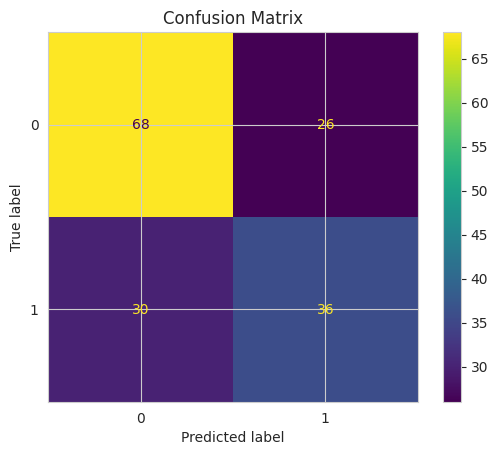

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix")
plt.show()

In [29]:
import pandas as pd

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(by='Importance', ascending=False)

print(importance)

                    Feature  Importance
2         MonthlyChargesINR    0.082922
3           TotalChargesINR    0.079037
1              TenureMonths    0.074988
0                       Age    0.072547
5              LatePayments    0.062702
..                      ...         ...
801  CustomerID_CUST-100797    0.000000
15   CustomerID_CUST-100011    0.000000
12   CustomerID_CUST-100008    0.000000
249  CustomerID_CUST-100245    0.000000
800  CustomerID_CUST-100796    0.000000

[817 rows x 2 columns]


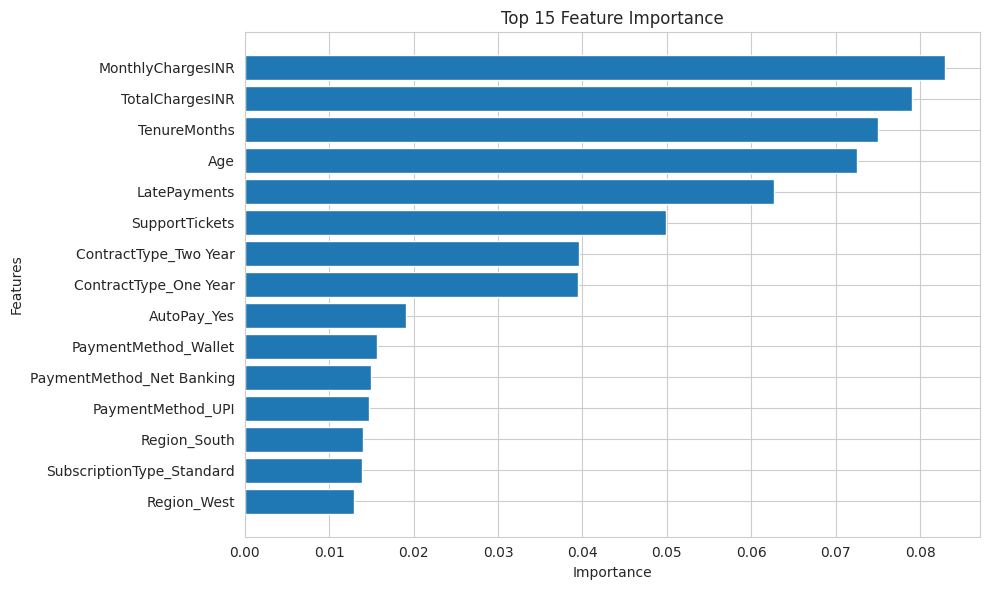

In [31]:
plt.figure(figsize=(10, 6))

top_features = importance.head(15)

plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [32]:
import joblib

joblib.dump(model, 'churn_prediction_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [33]:
from google.colab import files

files.download('churn_prediction_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>